# 03 - Neural Network Experiments

**Goal:** Train fully connected networks in Keras and measure the effect of each technique from Courses 1-2 (depth, regularization, optimizers, batch normalization, learning rate decay).

**Rules for a fair comparison**
- Same processed data as the baselines (`02_baselines`), same seed at the start of every experiment.
- Everything is evaluated on the **dev set**. The test set is used only once, at the end.
- Main metric: **macro F1** and per-class recall. Reference points from notebook 02: Logistic Regression 0.53, Random Forest 0.92.

## 0. Setup

In [27]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import tensorflow as tf

%load_ext autoreload
%autoreload 2
from src.data import load_processed
from src.models import build_model
from src.train import plot_compare
from src.experiments import run_experiment

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
SEED = 42
tf.keras.utils.set_random_seed(SEED)

## 1. Load the processed data

The arrays were saved by notebook 02 (labels 0-6, numeric features already standardized with training statistics).

In [3]:
data = load_processed()
X_train, y_train = data["X_train"], data["y_train"]
X_dev, y_dev = data["X_dev"], data["y_dev"]
X_test, y_test = data["X_test"], data["y_test"]

In [10]:
for name, arr in data.items():
    print(f"{name:8} shape={arr.shape} dtype={arr.dtype}")

print("classes:", np.unique(y_train))

X_train  shape=(464809, 54) dtype=float32
X_dev    shape=(58101, 54) dtype=float32
X_test   shape=(58102, 54) dtype=float32
y_train  shape=(464809,) dtype=int64
y_dev    shape=(58101,) dtype=int64
y_test   shape=(58102,) dtype=int64
classes: [0 1 2 3 4 5 6]


## 2. First model: one hidden layer

Architecture: 54 inputs -> Dense(64, ReLU, He initialization) -> Dense(7, softmax). It has 3,975 parameters.

Training setup (kept the same for the first experiments): Adam (learning rate 0.001), mini-batches of 512, 20 epochs, `sparse_categorical_crossentropy` loss (labels are integers 0-6).

In [11]:
model = build_model([64])
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 64)             │         3,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,975 (15.53 KB)

 Trainable params: 3,975 (15.53 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Experiments

`results` collects the dev metrics of every experiment, to build the final comparison table.

In [19]:
results = []

Epoch 1/20
908/908 - 39s - 43ms/step - accuracy: 0.7055 - loss: 0.7299 - val_accuracy: 0.7452 - val_loss: 0.6039
Epoch 2/20
908/908 - 4s - 4ms/step - accuracy: 0.7525 - loss: 0.5799 - val_accuracy: 0.7618 - val_loss: 0.5614
Epoch 3/20
908/908 - 3s - 3ms/step - accuracy: 0.7667 - loss: 0.5467 - val_accuracy: 0.7739 - val_loss: 0.5350
Epoch 4/20
908/908 - 3s - 4ms/step - accuracy: 0.7769 - loss: 0.5244 - val_accuracy: 0.7821 - val_loss: 0.5164
Epoch 5/20
908/908 - 5s - 6ms/step - accuracy: 0.7838 - loss: 0.5081 - val_accuracy: 0.7873 - val_loss: 0.5021
Epoch 6/20
908/908 - 3s - 3ms/step - accuracy: 0.7890 - loss: 0.4954 - val_accuracy: 0.7916 - val_loss: 0.4907
Epoch 7/20
908/908 - 3s - 4ms/step - accuracy: 0.7935 - loss: 0.4853 - val_accuracy: 0.7943 - val_loss: 0.4816
Epoch 8/20
908/908 - 3s - 4ms/step - accuracy: 0.7966 - loss: 0.4771 - val_accuracy: 0.7973 - val_loss: 0.4743
Epoch 9/20
908/908 - 3s - 3ms/step - accuracy: 0.7996 - loss: 0.4701 - val_accuracy: 0.8011 - val_loss: 0.4679

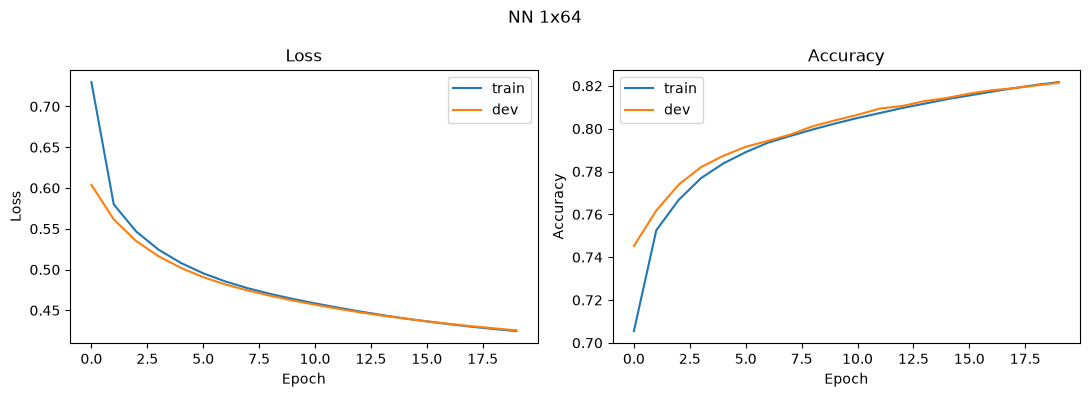

=== NN 1x64 ===
              precision    recall  f1-score   support

           0       0.84      0.77      0.81     21184
           1       0.82      0.89      0.85     28330
           2       0.80      0.83      0.82      3575
           3       0.77      0.66      0.71       275
           4       0.76      0.36      0.49       950
           5       0.66      0.59      0.62      1736
           6       0.85      0.82      0.83      2051

    accuracy                           0.82     58101
   macro avg       0.78      0.70      0.73     58101
weighted avg       0.82      0.82      0.82     58101



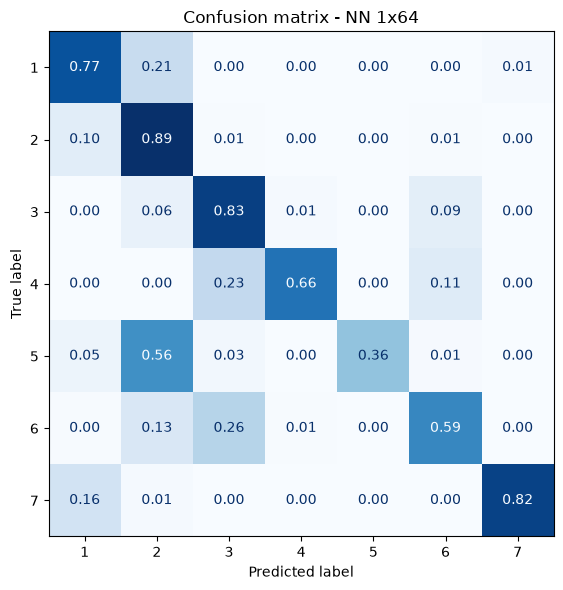

<Sequential name=sequential_4, built=True>

In [20]:
run_experiment("NN 1x64", [64], data, results)

**Observations (1 hidden layer, 64 units)**
- Train and dev curves are almost identical (train accuracy 0.822, dev accuracy 0.821), so there is no overfitting.
- Both are still improving at epoch 20: the model is **underfitting** and has not converged.
- Macro F1 is about 0.73: much better than Logistic Regression (0.53), but far from Random Forest (0.92).
- The training error (about 18%) is much higher than the Random Forest error (about 4.6%), so the main problem is **high bias**. Regularization will not help yet. The model needs more capacity or more training.
- Confusion matrix (original class names 1-7): class 5 is the hardest (recall 0.36, and 56% of it is predicted as class 2). Class 6 has recall 0.59 (26% predicted as class 3) and class 4 has recall 0.66 (23% predicted as class 3). Classes 1 and 2 are mixed in both directions (21% of class 1 predicted as class 2).
- Compared with Logistic Regression, all small classes improved, so the hidden layer is learning non-linear patterns.

Note: the classification report uses labels 0-6 (`Cover_Type` minus 1).

### Experiment 2: deeper and wider networks

Since the first model underfits, I increase the capacity: 2, 3 and 4 hidden layers with more neurons. Everything else stays the same (Adam, learning rate 0.001, batch size 512, 20 epochs, same seed).

Epoch 1/20
908/908 - 7s - 8ms/step - accuracy: 0.7422 - loss: 0.6183 - val_accuracy: 0.7806 - val_loss: 0.5196
Epoch 2/20
908/908 - 4s - 5ms/step - accuracy: 0.7935 - loss: 0.4871 - val_accuracy: 0.8049 - val_loss: 0.4618
Epoch 3/20
908/908 - 5s - 5ms/step - accuracy: 0.8139 - loss: 0.4424 - val_accuracy: 0.8211 - val_loss: 0.4265
Epoch 4/20
908/908 - 4s - 5ms/step - accuracy: 0.8283 - loss: 0.4119 - val_accuracy: 0.8317 - val_loss: 0.4019
Epoch 5/20
908/908 - 4s - 5ms/step - accuracy: 0.8384 - loss: 0.3897 - val_accuracy: 0.8394 - val_loss: 0.3848
Epoch 6/20
908/908 - 5s - 5ms/step - accuracy: 0.8461 - loss: 0.3723 - val_accuracy: 0.8457 - val_loss: 0.3704
Epoch 7/20
908/908 - 4s - 5ms/step - accuracy: 0.8524 - loss: 0.3580 - val_accuracy: 0.8513 - val_loss: 0.3591
Epoch 8/20
908/908 - 4s - 5ms/step - accuracy: 0.8574 - loss: 0.3462 - val_accuracy: 0.8546 - val_loss: 0.3496
Epoch 9/20
908/908 - 5s - 6ms/step - accuracy: 0.8622 - loss: 0.3363 - val_accuracy: 0.8579 - val_loss: 0.3422
E

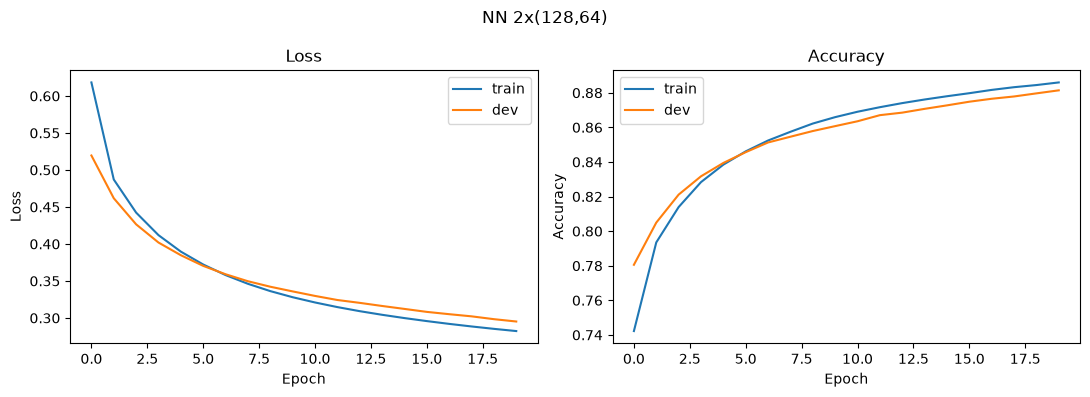

=== NN 2x(128,64) ===
              precision    recall  f1-score   support

           0       0.89      0.88      0.88     21184
           1       0.90      0.90      0.90     28330
           2       0.78      0.95      0.86      3575
           3       0.90      0.62      0.73       275
           4       0.78      0.64      0.70       950
           5       0.76      0.62      0.69      1736
           6       0.90      0.89      0.90      2051

    accuracy                           0.88     58101
   macro avg       0.84      0.79      0.81     58101
weighted avg       0.88      0.88      0.88     58101



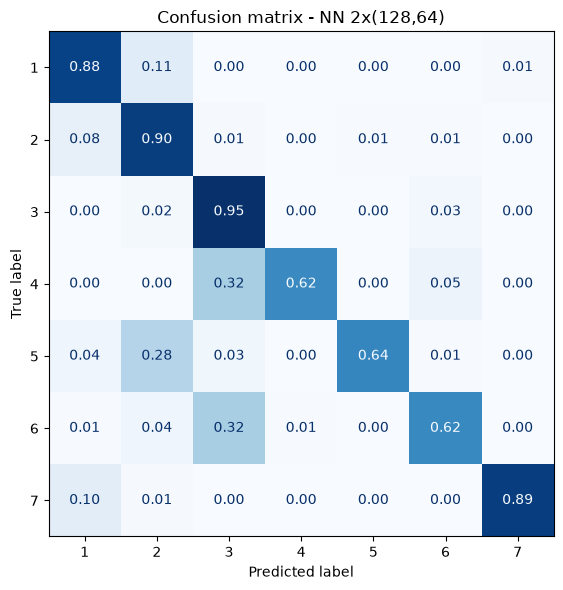

<Sequential name=sequential_5, built=True>

In [21]:
run_experiment("NN 2x(128,64)", [128, 64], data, results)

Epoch 1/20
908/908 - 9s - 10ms/step - accuracy: 0.7720 - loss: 0.5414 - val_accuracy: 0.8155 - val_loss: 0.4415
Epoch 2/20
908/908 - 6s - 7ms/step - accuracy: 0.8317 - loss: 0.4015 - val_accuracy: 0.8434 - val_loss: 0.3765
Epoch 3/20
908/908 - 6s - 6ms/step - accuracy: 0.8540 - loss: 0.3515 - val_accuracy: 0.8579 - val_loss: 0.3427
Epoch 4/20
908/908 - 6s - 6ms/step - accuracy: 0.8676 - loss: 0.3204 - val_accuracy: 0.8689 - val_loss: 0.3183
Epoch 5/20
908/908 - 6s - 6ms/step - accuracy: 0.8776 - loss: 0.2978 - val_accuracy: 0.8764 - val_loss: 0.3019
Epoch 6/20
908/908 - 6s - 7ms/step - accuracy: 0.8856 - loss: 0.2798 - val_accuracy: 0.8826 - val_loss: 0.2883
Epoch 7/20
908/908 - 6s - 6ms/step - accuracy: 0.8918 - loss: 0.2654 - val_accuracy: 0.8862 - val_loss: 0.2773
Epoch 8/20
908/908 - 10s - 11ms/step - accuracy: 0.8969 - loss: 0.2533 - val_accuracy: 0.8909 - val_loss: 0.2670
Epoch 9/20
908/908 - 6s - 6ms/step - accuracy: 0.9012 - loss: 0.2433 - val_accuracy: 0.8941 - val_loss: 0.258

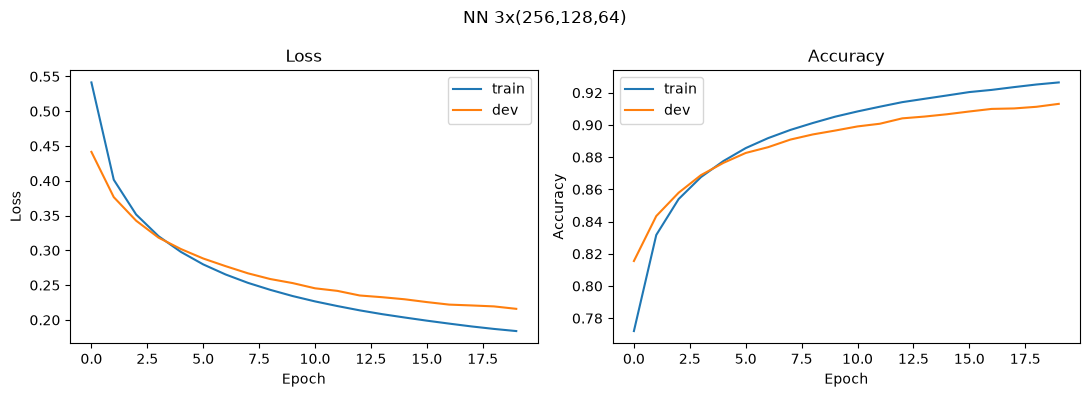

=== NN 3x(256,128,64) ===
              precision    recall  f1-score   support

           0       0.94      0.88      0.91     21184
           1       0.92      0.94      0.93     28330
           2       0.82      0.96      0.88      3575
           3       0.90      0.66      0.76       275
           4       0.85      0.77      0.81       950
           5       0.82      0.79      0.81      1736
           6       0.87      0.97      0.92      2051

    accuracy                           0.91     58101
   macro avg       0.87      0.85      0.86     58101
weighted avg       0.91      0.91      0.91     58101



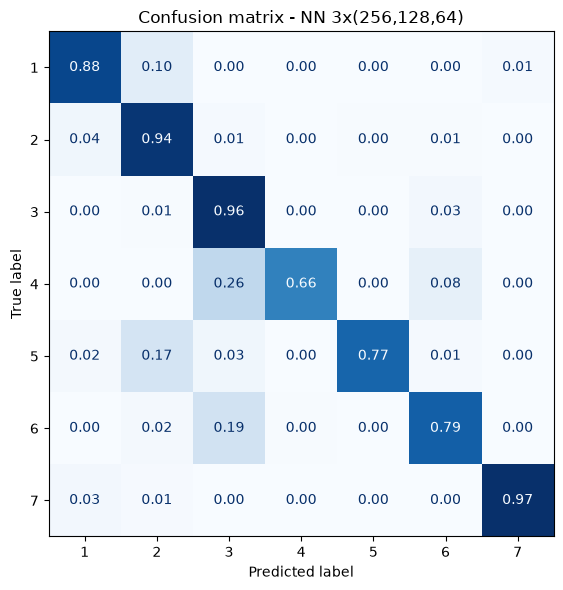

<Sequential name=sequential_6, built=True>

In [22]:
run_experiment("NN 3x(256,128,64)", [256, 128, 64], data, results)

Epoch 1/20
908/908 - 16s - 18ms/step - accuracy: 0.7925 - loss: 0.4908 - val_accuracy: 0.8392 - val_loss: 0.3894
Epoch 2/20
908/908 - 14s - 15ms/step - accuracy: 0.8529 - loss: 0.3522 - val_accuracy: 0.8679 - val_loss: 0.3212
Epoch 3/20
908/908 - 21s - 23ms/step - accuracy: 0.8778 - loss: 0.2963 - val_accuracy: 0.8846 - val_loss: 0.2858
Epoch 4/20
908/908 - 20s - 22ms/step - accuracy: 0.8935 - loss: 0.2610 - val_accuracy: 0.8929 - val_loss: 0.2648
Epoch 5/20
908/908 - 21s - 23ms/step - accuracy: 0.9044 - loss: 0.2363 - val_accuracy: 0.8995 - val_loss: 0.2498
Epoch 6/20
908/908 - 14s - 15ms/step - accuracy: 0.9122 - loss: 0.2175 - val_accuracy: 0.9071 - val_loss: 0.2316
Epoch 7/20
908/908 - 13s - 14ms/step - accuracy: 0.9180 - loss: 0.2027 - val_accuracy: 0.9127 - val_loss: 0.2176
Epoch 8/20
908/908 - 13s - 15ms/step - accuracy: 0.9231 - loss: 0.1910 - val_accuracy: 0.9166 - val_loss: 0.2075
Epoch 9/20
908/908 - 13s - 14ms/step - accuracy: 0.9274 - loss: 0.1809 - val_accuracy: 0.9194 - 

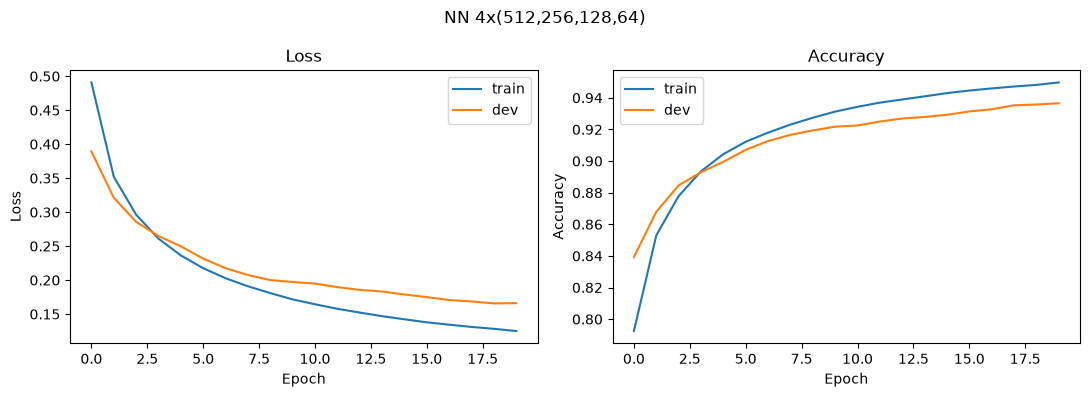

=== NN 4x(512,256,128,64) ===
              precision    recall  f1-score   support

           0       0.95      0.92      0.93     21184
           1       0.94      0.96      0.95     28330
           2       0.89      0.97      0.93      3575
           3       0.91      0.79      0.85       275
           4       0.87      0.81      0.84       950
           5       0.90      0.85      0.87      1736
           6       0.90      0.97      0.93      2051

    accuracy                           0.94     58101
   macro avg       0.91      0.89      0.90     58101
weighted avg       0.94      0.94      0.94     58101



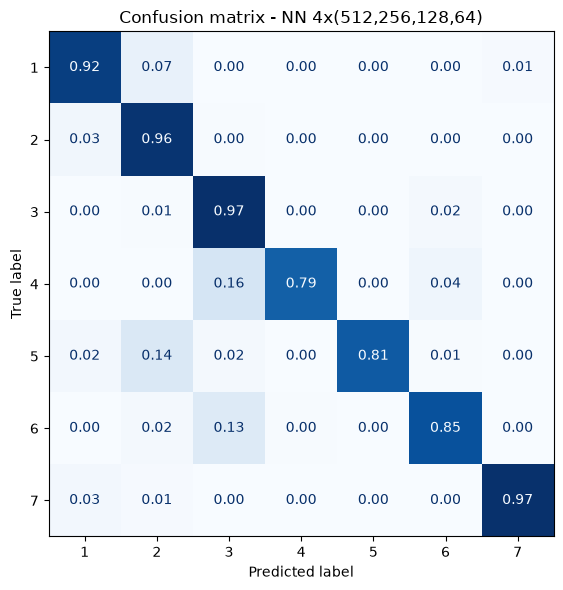

<Sequential name=sequential_7, built=True>

In [23]:
run_experiment("NN 4x(512,256,128,64)", [512, 256, 128, 64], data, results)

**Observations (capacity experiments, 20 epochs each)**
- More capacity improved the dev macro F1 at every step: 0.73 -> 0.81 -> 0.86 -> 0.90. Dev accuracy went from 0.82 to 0.94.
- Training accuracy also increased (0.82 -> 0.95), so the main problem was high bias, and a bigger network fixed most of it.
- The small classes benefited the most. For example, the recall of class 5 (the hardest) went from 0.36 to 0.81.
- A gap between train and dev appears and grows with the network size (about 0.4 points for 2 layers, 1.0 for 3 layers and 1.1 for 4 layers).
- The 4-layer model is still improving at epoch 20, so I train it longer.

### Experiment 3: train longer

The best architecture so far (4 hidden layers) trained for 60 epochs instead of 20.

Epoch 1/60
908/908 - 17s - 18ms/step - accuracy: 0.7925 - loss: 0.4908 - val_accuracy: 0.8392 - val_loss: 0.3894
Epoch 2/60
908/908 - 15s - 16ms/step - accuracy: 0.8529 - loss: 0.3522 - val_accuracy: 0.8679 - val_loss: 0.3212
Epoch 3/60
908/908 - 13s - 15ms/step - accuracy: 0.8778 - loss: 0.2963 - val_accuracy: 0.8846 - val_loss: 0.2858
Epoch 4/60
908/908 - 20s - 22ms/step - accuracy: 0.8935 - loss: 0.2610 - val_accuracy: 0.8929 - val_loss: 0.2648
Epoch 5/60
908/908 - 13s - 14ms/step - accuracy: 0.9044 - loss: 0.2363 - val_accuracy: 0.8995 - val_loss: 0.2498
Epoch 6/60
908/908 - 13s - 14ms/step - accuracy: 0.9122 - loss: 0.2175 - val_accuracy: 0.9071 - val_loss: 0.2316
Epoch 7/60
908/908 - 14s - 15ms/step - accuracy: 0.9180 - loss: 0.2027 - val_accuracy: 0.9127 - val_loss: 0.2176
Epoch 8/60
908/908 - 14s - 15ms/step - accuracy: 0.9231 - loss: 0.1910 - val_accuracy: 0.9166 - val_loss: 0.2075
Epoch 9/60
908/908 - 20s - 22ms/step - accuracy: 0.9274 - loss: 0.1809 - val_accuracy: 0.9194 - 

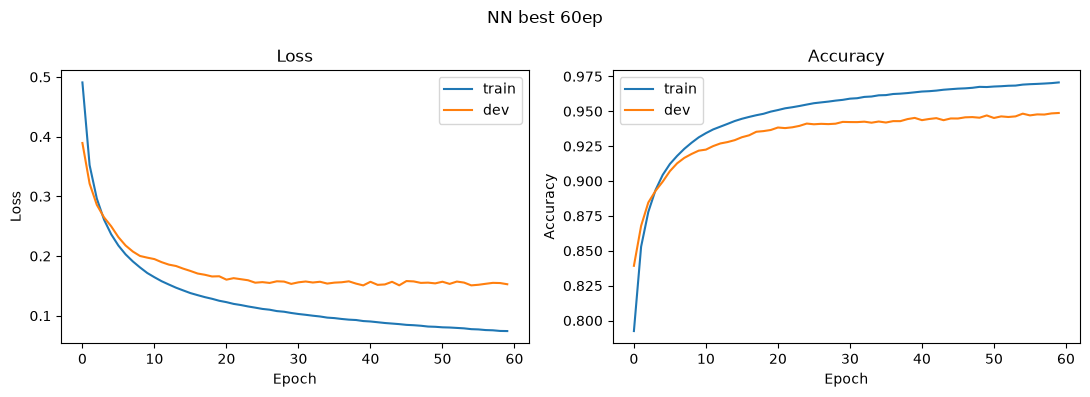

=== NN best 60ep ===
              precision    recall  f1-score   support

           0       0.95      0.95      0.95     21184
           1       0.96      0.96      0.96     28330
           2       0.93      0.96      0.95      3575
           3       0.90      0.82      0.86       275
           4       0.87      0.85      0.86       950
           5       0.91      0.88      0.90      1736
           6       0.95      0.95      0.95      2051

    accuracy                           0.95     58101
   macro avg       0.92      0.91      0.92     58101
weighted avg       0.95      0.95      0.95     58101



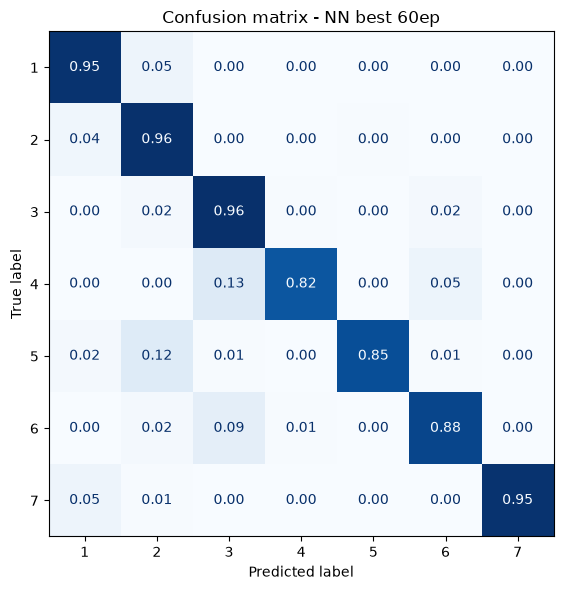

<Sequential name=sequential_8, built=True>

In [24]:
run_experiment("NN best 60ep", [512, 256, 128, 64], data, results, epochs=60)

**Observations (4 hidden layers, 60 epochs)**
- Dev macro F1 rose from 0.90 to 0.916 and dev accuracy to 0.949, very close to Random Forest (macro F1 0.923, accuracy 0.954).
- The curves show the start of **overfitting**: the train loss keeps falling (0.074 at epoch 60) but the dev loss stops improving after about epoch 20 (around 0.155). The accuracy gap is 1.6 points (train 0.964, dev 0.949).
- The training error (3.6%) is already lower than the Random Forest dev error (4.6%), so bias is no longer the main problem. The remaining gap is **variance**, which is what regularization is for.
- Every class has recall of at least 0.82. The hardest are class 4 (0.82, 13% predicted as class 3), class 5 (0.85, 12% predicted as class 2) and class 6 (0.88, 9% predicted as class 3). Class 5 is better than with Random Forest (0.85 vs 0.77), and class 4 is similar (0.82 vs 0.83).

## 4. Comparison table

`train_acc` is the accuracy on the full training set after training, and `accuracy` / `macro_f1` are on the dev set. The gap between them shows how much the model overfits.

In [25]:
results_df = pd.DataFrame(results)
results_df

,model,accuracy,macro_f1,params,train_acc
0,NN 1x64,0.821414,0.733075,3975,0.822314
1,"NN 2x(128,64)",0.881413,0.808019,15751,0.885615
2,"NN 3x(256,128,64)",0.913100,0.859446,55687,0.922659
3,"NN 4x(512,256,128,64)",0.936559,0.900783,201095,0.947830
4,NN best 60ep,0.948744,0.916265,201095,0.964471


In [26]:
pd.DataFrame(results).to_csv("../results/nn_results.csv", index=False)

**Takeaways so far**
- Capacity was the first bottleneck: going from 1 hidden layer to 4 raised the dev macro F1 from 0.73 to 0.90 (0.92 with more epochs).
- The 4-layer network (60 epochs) is close to Random Forest (0.916 vs 0.923 macro F1) but does not beat it yet.
- The train/dev gap and the flat dev loss show overfitting. This network (4 layers, 60 epochs) is the **reference model** for the next experiments: L2 and Dropout, then optimizers, batch normalization and learning rate decay.

In [4]:
if "results" not in globals():
    results = pd.read_csv("../results/nn_results.csv").to_dict("records")

### Experiment 4: regularization

The reference model (4 hidden layers, 60 epochs) starts to overfit, so I test L2 regularization (1e-4) and Dropout (rate 0.2, applied after each hidden layer). Same architecture, same seed, same 60 epochs.

Epoch 1/60
908/908 - 28s - 31ms/step - accuracy: 0.7883 - loss: 0.6344 - val_accuracy: 0.8307 - val_loss: 0.5163
Epoch 2/60
908/908 - 15s - 17ms/step - accuracy: 0.8440 - loss: 0.4795 - val_accuracy: 0.8601 - val_loss: 0.4422
Epoch 3/60
908/908 - 15s - 16ms/step - accuracy: 0.8664 - loss: 0.4233 - val_accuracy: 0.8750 - val_loss: 0.4049
Epoch 4/60
908/908 - 20s - 22ms/step - accuracy: 0.8812 - loss: 0.3880 - val_accuracy: 0.8819 - val_loss: 0.3870
Epoch 5/60
908/908 - 15s - 17ms/step - accuracy: 0.8916 - loss: 0.3631 - val_accuracy: 0.8875 - val_loss: 0.3690
Epoch 6/60
908/908 - 15s - 16ms/step - accuracy: 0.8989 - loss: 0.3442 - val_accuracy: 0.8918 - val_loss: 0.3568
Epoch 7/60
908/908 - 21s - 23ms/step - accuracy: 0.9041 - loss: 0.3303 - val_accuracy: 0.8965 - val_loss: 0.3448
Epoch 8/60
908/908 - 15s - 17ms/step - accuracy: 0.9085 - loss: 0.3187 - val_accuracy: 0.9002 - val_loss: 0.3352
Epoch 9/60
908/908 - 20s - 22ms/step - accuracy: 0.9121 - loss: 0.3093 - val_accuracy: 0.9057 - 

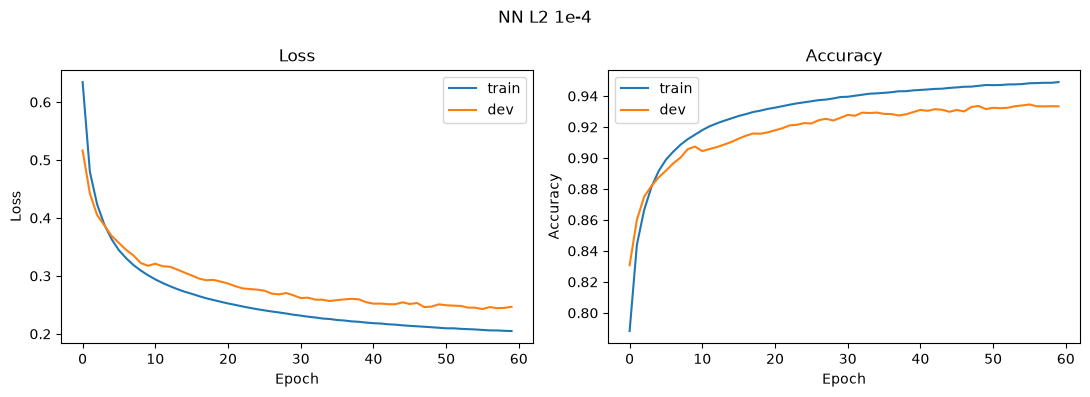

=== NN L2 1e-4 ===
              precision    recall  f1-score   support

           0       0.94      0.93      0.93     21184
           1       0.95      0.94      0.95     28330
           2       0.86      0.98      0.91      3575
           3       0.90      0.72      0.80       275
           4       0.82      0.84      0.83       950
           5       0.93      0.77      0.84      1736
           6       0.93      0.94      0.94      2051

    accuracy                           0.93     58101
   macro avg       0.90      0.88      0.89     58101
weighted avg       0.93      0.93      0.93     58101



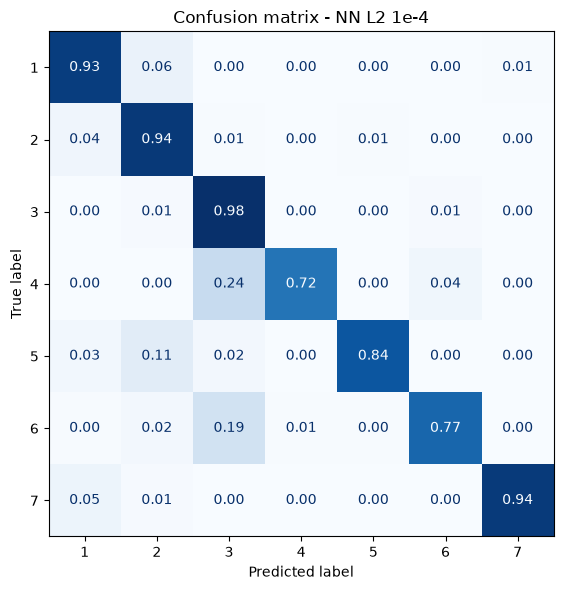

<Sequential name=sequential_1, built=True>

In [7]:
run_experiment("NN L2 1e-4", [512, 256, 128, 64], data, results, epochs=60, l2=1e-4)

Epoch 1/60
908/908 - 25s - 28ms/step - accuracy: 0.7313 - loss: 0.6359 - val_accuracy: 0.7932 - val_loss: 0.4809
Epoch 2/60
908/908 - 19s - 21ms/step - accuracy: 0.7891 - loss: 0.4917 - val_accuracy: 0.8291 - val_loss: 0.4005
Epoch 3/60
908/908 - 18s - 20ms/step - accuracy: 0.8151 - loss: 0.4355 - val_accuracy: 0.8495 - val_loss: 0.3581
Epoch 4/60
908/908 - 18s - 20ms/step - accuracy: 0.8329 - loss: 0.3970 - val_accuracy: 0.8641 - val_loss: 0.3252
Epoch 5/60
908/908 - 21s - 23ms/step - accuracy: 0.8443 - loss: 0.3707 - val_accuracy: 0.8736 - val_loss: 0.3020
Epoch 6/60
908/908 - 19s - 20ms/step - accuracy: 0.8538 - loss: 0.3500 - val_accuracy: 0.8817 - val_loss: 0.2834
Epoch 7/60
908/908 - 21s - 23ms/step - accuracy: 0.8612 - loss: 0.3335 - val_accuracy: 0.8910 - val_loss: 0.2675
Epoch 8/60
908/908 - 18s - 20ms/step - accuracy: 0.8679 - loss: 0.3195 - val_accuracy: 0.8957 - val_loss: 0.2527
Epoch 9/60
908/908 - 20s - 22ms/step - accuracy: 0.8724 - loss: 0.3089 - val_accuracy: 0.9008 - 

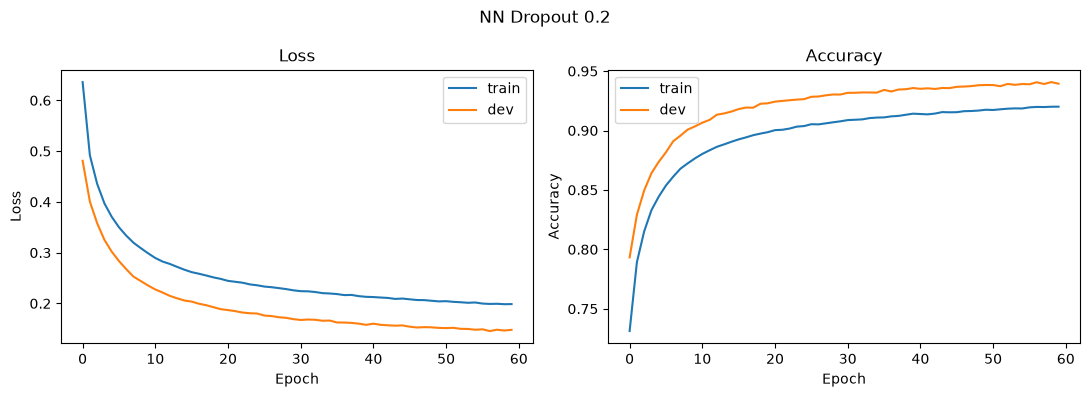

=== NN Dropout 0.2 ===
              precision    recall  f1-score   support

           0       0.95      0.92      0.94     21184
           1       0.94      0.96      0.95     28330
           2       0.93      0.95      0.94      3575
           3       0.88      0.82      0.85       275
           4       0.86      0.83      0.85       950
           5       0.92      0.87      0.89      1736
           6       0.93      0.95      0.94      2051

    accuracy                           0.94     58101
   macro avg       0.92      0.90      0.91     58101
weighted avg       0.94      0.94      0.94     58101



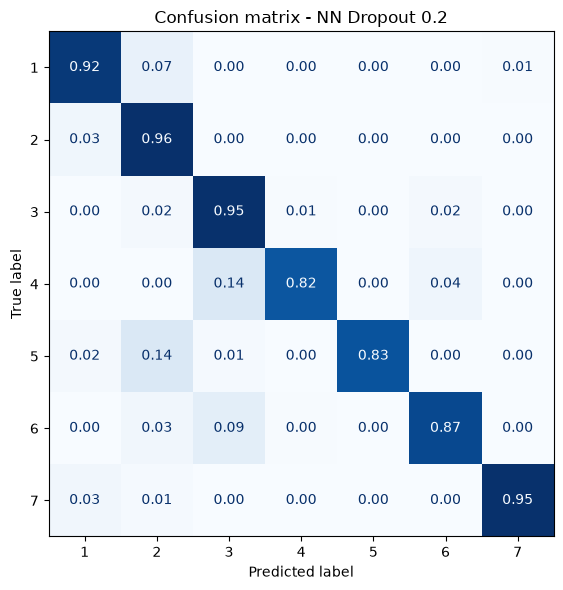

<Sequential name=sequential_2, built=True>

In [8]:
run_experiment("NN Dropout 0.2", [512, 256, 128, 64], data, results, epochs=60, dropout=0.2)

**Observations (regularization, 4 layers, 60 epochs)**
- Neither setting beat the reference model (dev accuracy 0.949, macro F1 0.916) at 60 epochs.
- The train/dev accuracy gap did shrink: 1.6 points for the reference, 1.1 for L2 and 0.9 for Dropout. But dev accuracy also went down, so the smaller gap did not turn into a better model.
- **L2 (1e-4)** hurt: dev accuracy 0.933 and macro F1 about 0.89. The dev loss stops improving much after epoch 40 (around 0.25), and the small classes lost the most: recall of class 4 fell from 0.82 to 0.72 and class 6 from 0.88 to 0.77. This strength is too high: it limits the capacity the rare classes need.
- **Dropout (0.2)** removed the plateau: the dev loss keeps decreasing until epoch 60 (0.148, versus about 0.153 for the reference), but dev accuracy (0.939) and macro F1 (about 0.91) are slightly lower than the reference. The train curve is below the dev curve because dropout is active only during training. Both curves are still improving, so this model needs more epochs.
- At a fixed budget of 60 epochs, the unregularized model is still the best. The regularization strengths (L2, dropout rate) will be tuned later in the random search, together with the learning rate and layer sizes.

In [15]:
pd.DataFrame(results).to_csv("../results/nn_results.csv", index=False)

In [14]:
if "results" not in globals():
    results = pd.read_csv("../results/nn_results.csv").to_dict("records")

### Experiment 5: optimizers

Same architecture (4 hidden layers), batch size 512, same seed, 30 epochs. Learning rates: SGD 0.1, Momentum 0.01 (beta 0.9, a similar effective step size), RMSprop 0.001, Adam 0.001. Each optimizer uses a single learning rate, so the comparison depends on these choices.

In [20]:
histories = {}

Epoch 1/30
908/908 - 15s - 16ms/step - accuracy: 0.7384 - loss: 0.6110 - val_accuracy: 0.7807 - val_loss: 0.5145
Epoch 2/30
908/908 - 15s - 16ms/step - accuracy: 0.7930 - loss: 0.4836 - val_accuracy: 0.8113 - val_loss: 0.4540
Epoch 3/30
908/908 - 13s - 14ms/step - accuracy: 0.8194 - loss: 0.4259 - val_accuracy: 0.8278 - val_loss: 0.4143
Epoch 4/30
908/908 - 20s - 22ms/step - accuracy: 0.8389 - loss: 0.3842 - val_accuracy: 0.8472 - val_loss: 0.3705
Epoch 5/30
908/908 - 11s - 13ms/step - accuracy: 0.8535 - loss: 0.3523 - val_accuracy: 0.8587 - val_loss: 0.3492
Epoch 6/30
908/908 - 12s - 13ms/step - accuracy: 0.8651 - loss: 0.3270 - val_accuracy: 0.8655 - val_loss: 0.3312
Epoch 7/30
908/908 - 11s - 12ms/step - accuracy: 0.8745 - loss: 0.3053 - val_accuracy: 0.8576 - val_loss: 0.3480
Epoch 8/30
908/908 - 11s - 12ms/step - accuracy: 0.8822 - loss: 0.2889 - val_accuracy: 0.8691 - val_loss: 0.3233
Epoch 9/30
908/908 - 15s - 16ms/step - accuracy: 0.8884 - loss: 0.2739 - val_accuracy: 0.8767 - 

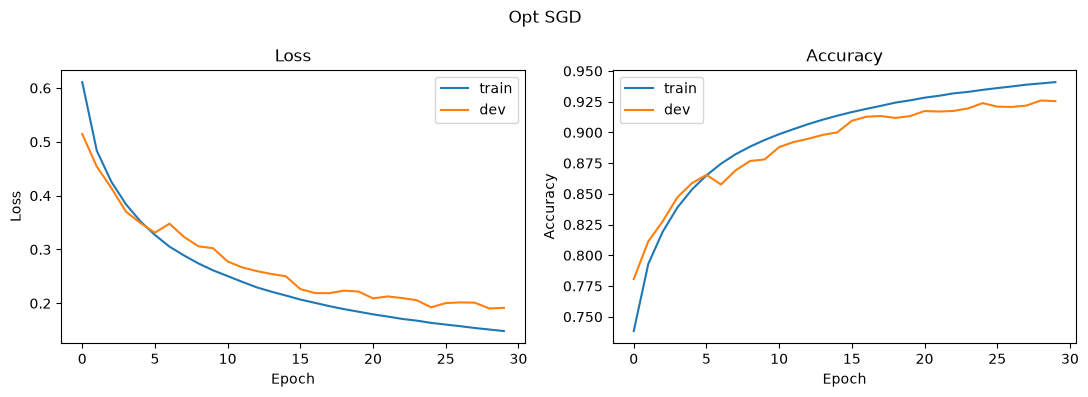

=== Opt SGD ===
              precision    recall  f1-score   support

           0       0.96      0.89      0.92     21184
           1       0.91      0.97      0.94     28330
           2       0.90      0.91      0.90      3575
           3       0.80      0.86      0.83       275
           4       0.88      0.75      0.81       950
           5       0.88      0.78      0.82      1736
           6       0.94      0.94      0.94      2051

    accuracy                           0.93     58101
   macro avg       0.89      0.87      0.88     58101
weighted avg       0.93      0.93      0.92     58101



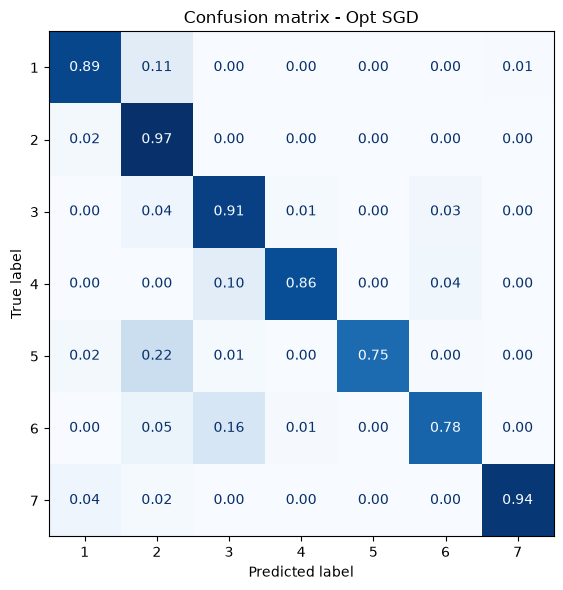

<Sequential name=sequential_5, built=True>

In [21]:
run_experiment("Opt SGD", [512, 256, 128, 64], data, results,
               epochs=30, optimizer="sgd", learning_rate=0.1, histories=histories)

Epoch 1/30
908/908 - 15s - 17ms/step - accuracy: 0.7526 - loss: 0.5902 - val_accuracy: 0.7943 - val_loss: 0.4897
Epoch 2/30
908/908 - 20s - 22ms/step - accuracy: 0.8091 - loss: 0.4549 - val_accuracy: 0.8198 - val_loss: 0.4265
Epoch 3/30
908/908 - 13s - 14ms/step - accuracy: 0.8335 - loss: 0.3992 - val_accuracy: 0.8434 - val_loss: 0.3776
Epoch 4/30
908/908 - 20s - 22ms/step - accuracy: 0.8508 - loss: 0.3612 - val_accuracy: 0.8556 - val_loss: 0.3495
Epoch 5/30
908/908 - 13s - 15ms/step - accuracy: 0.8637 - loss: 0.3320 - val_accuracy: 0.8658 - val_loss: 0.3261
Epoch 6/30
908/908 - 16s - 18ms/step - accuracy: 0.8734 - loss: 0.3095 - val_accuracy: 0.8740 - val_loss: 0.3091
Epoch 7/30
908/908 - 14s - 15ms/step - accuracy: 0.8814 - loss: 0.2907 - val_accuracy: 0.8815 - val_loss: 0.2935
Epoch 8/30
908/908 - 14s - 16ms/step - accuracy: 0.8877 - loss: 0.2754 - val_accuracy: 0.8847 - val_loss: 0.2836
Epoch 9/30
908/908 - 13s - 15ms/step - accuracy: 0.8937 - loss: 0.2624 - val_accuracy: 0.8868 - 

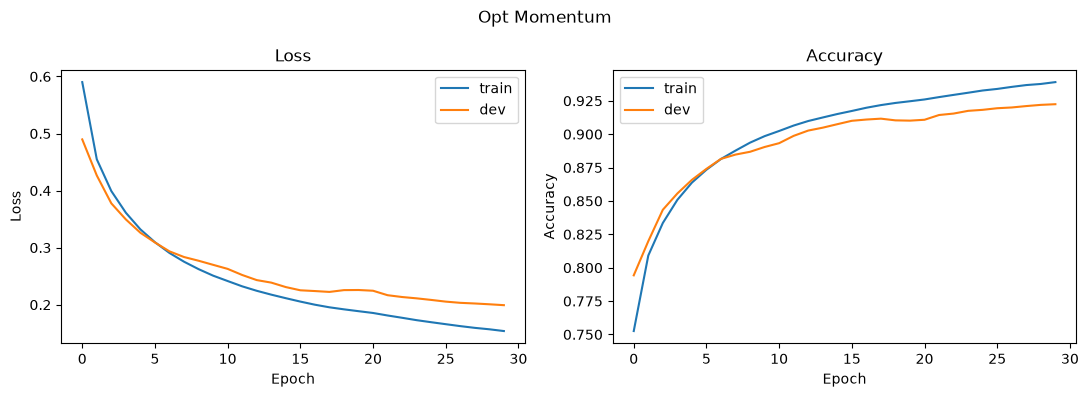

=== Opt Momentum ===
              precision    recall  f1-score   support

           0       0.95      0.89      0.92     21184
           1       0.92      0.96      0.94     28330
           2       0.89      0.94      0.91      3575
           3       0.86      0.73      0.79       275
           4       0.78      0.83      0.80       950
           5       0.84      0.81      0.83      1736
           6       0.89      0.96      0.93      2051

    accuracy                           0.92     58101
   macro avg       0.88      0.87      0.87     58101
weighted avg       0.92      0.92      0.92     58101



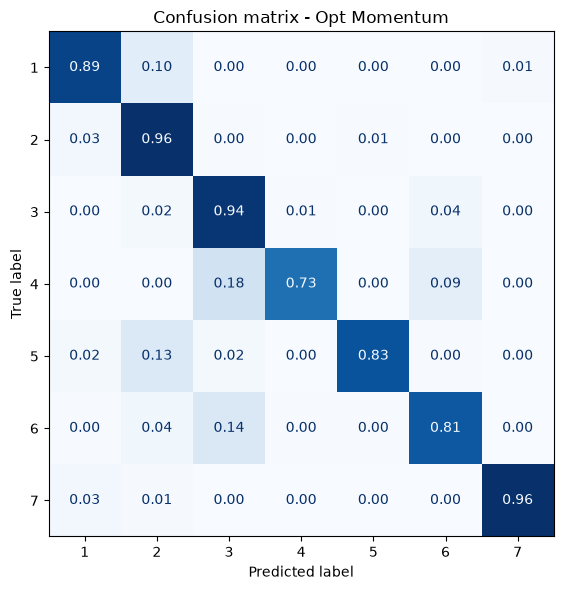

<Sequential name=sequential_6, built=True>

In [22]:
run_experiment("Opt Momentum", [512, 256, 128, 64], data, results,
               epochs=30, optimizer="momentum", learning_rate=0.01, histories=histories)

Epoch 1/30
908/908 - 17s - 19ms/step - accuracy: 0.7775 - loss: 0.5197 - val_accuracy: 0.8296 - val_loss: 0.4056
Epoch 2/30
908/908 - 11s - 12ms/step - accuracy: 0.8489 - loss: 0.3617 - val_accuracy: 0.8634 - val_loss: 0.3324
Epoch 3/30
908/908 - 11s - 12ms/step - accuracy: 0.8775 - loss: 0.2975 - val_accuracy: 0.8803 - val_loss: 0.2946
Epoch 4/30
908/908 - 11s - 13ms/step - accuracy: 0.8942 - loss: 0.2585 - val_accuracy: 0.8922 - val_loss: 0.2691
Epoch 5/30
908/908 - 14s - 15ms/step - accuracy: 0.9058 - loss: 0.2315 - val_accuracy: 0.8986 - val_loss: 0.2553
Epoch 6/30
908/908 - 13s - 14ms/step - accuracy: 0.9139 - loss: 0.2118 - val_accuracy: 0.9056 - val_loss: 0.2343
Epoch 7/30
908/908 - 20s - 22ms/step - accuracy: 0.9204 - loss: 0.1966 - val_accuracy: 0.9132 - val_loss: 0.2192
Epoch 8/30
908/908 - 12s - 14ms/step - accuracy: 0.9255 - loss: 0.1846 - val_accuracy: 0.9169 - val_loss: 0.2071
Epoch 9/30
908/908 - 12s - 13ms/step - accuracy: 0.9297 - loss: 0.1744 - val_accuracy: 0.9186 - 

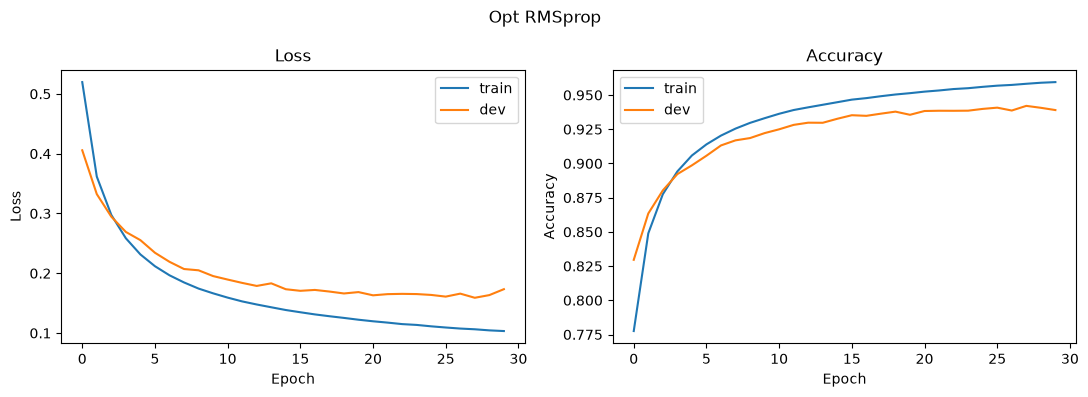

=== Opt RMSprop ===
              precision    recall  f1-score   support

           0       0.96      0.91      0.94     21184
           1       0.94      0.96      0.95     28330
           2       0.91      0.96      0.93      3575
           3       0.83      0.81      0.82       275
           4       0.83      0.85      0.84       950
           5       0.93      0.82      0.87      1736
           6       0.90      0.97      0.93      2051

    accuracy                           0.94     58101
   macro avg       0.90      0.90      0.90     58101
weighted avg       0.94      0.94      0.94     58101



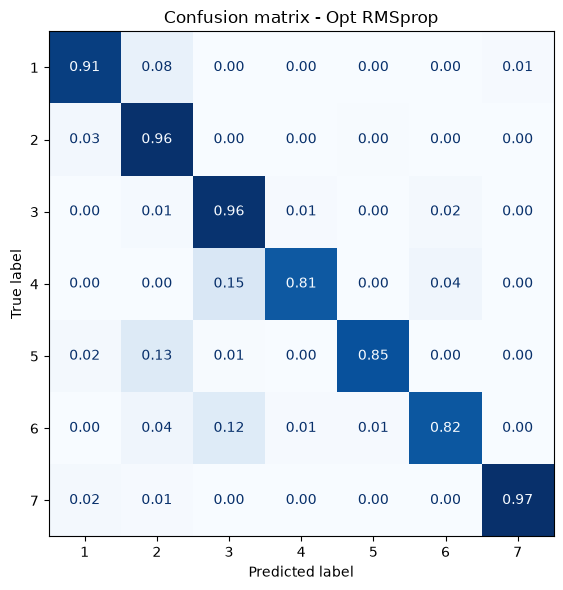

<Sequential name=sequential_7, built=True>

In [23]:
run_experiment("Opt RMSprop", [512, 256, 128, 64], data, results,
               epochs=30, optimizer="rmsprop", learning_rate=1e-3, histories=histories)

Epoch 1/30
908/908 - 16s - 17ms/step - accuracy: 0.7925 - loss: 0.4908 - val_accuracy: 0.8392 - val_loss: 0.3894
Epoch 2/30
908/908 - 13s - 14ms/step - accuracy: 0.8529 - loss: 0.3522 - val_accuracy: 0.8679 - val_loss: 0.3212
Epoch 3/30
908/908 - 20s - 22ms/step - accuracy: 0.8778 - loss: 0.2963 - val_accuracy: 0.8846 - val_loss: 0.2858
Epoch 4/30
908/908 - 13s - 14ms/step - accuracy: 0.8935 - loss: 0.2610 - val_accuracy: 0.8929 - val_loss: 0.2648
Epoch 5/30
908/908 - 13s - 14ms/step - accuracy: 0.9044 - loss: 0.2363 - val_accuracy: 0.8995 - val_loss: 0.2498
Epoch 6/30
908/908 - 13s - 14ms/step - accuracy: 0.9122 - loss: 0.2175 - val_accuracy: 0.9071 - val_loss: 0.2316
Epoch 7/30
908/908 - 13s - 14ms/step - accuracy: 0.9180 - loss: 0.2027 - val_accuracy: 0.9127 - val_loss: 0.2176
Epoch 8/30
908/908 - 13s - 14ms/step - accuracy: 0.9231 - loss: 0.1910 - val_accuracy: 0.9166 - val_loss: 0.2075
Epoch 9/30
908/908 - 13s - 14ms/step - accuracy: 0.9274 - loss: 0.1809 - val_accuracy: 0.9194 - 

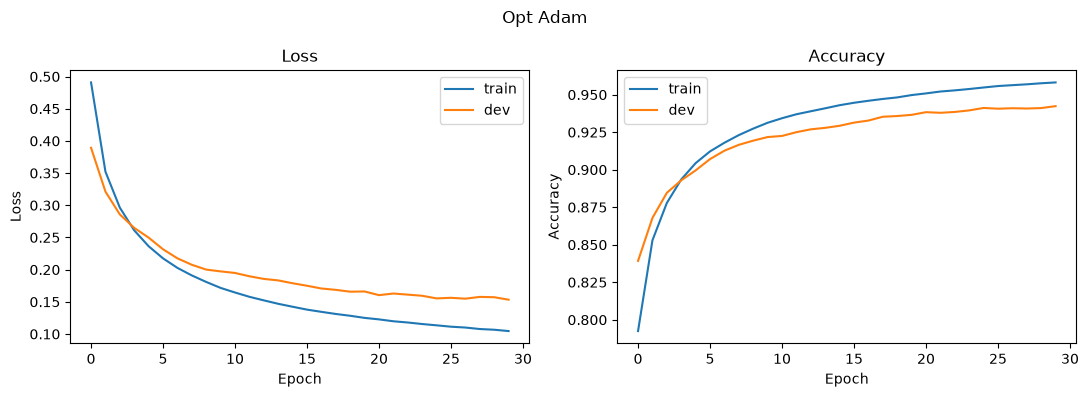

=== Opt Adam ===
              precision    recall  f1-score   support

           0       0.95      0.93      0.94     21184
           1       0.95      0.96      0.95     28330
           2       0.92      0.96      0.94      3575
           3       0.86      0.81      0.83       275
           4       0.83      0.85      0.84       950
           5       0.90      0.87      0.88      1736
           6       0.93      0.96      0.94      2051

    accuracy                           0.94     58101
   macro avg       0.90      0.90      0.90     58101
weighted avg       0.94      0.94      0.94     58101



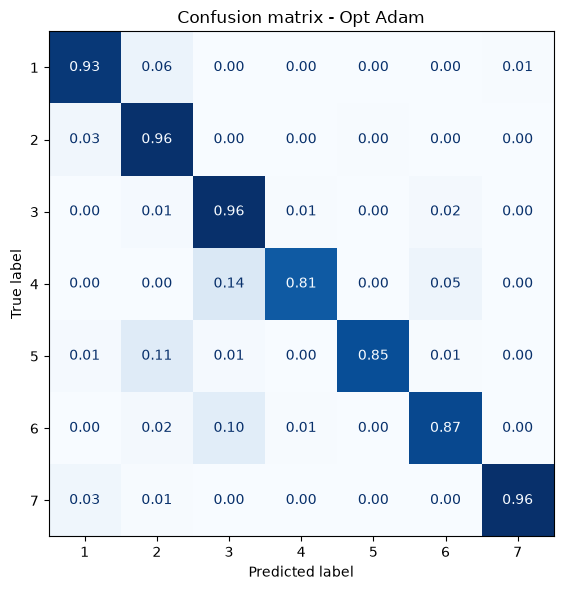

<Sequential name=sequential_8, built=True>

In [24]:
run_experiment("Opt Adam", [512, 256, 128, 64], data, results,
               epochs=30, optimizer="adam", learning_rate=1e-3, histories=histories)

**Observations (optimizers, 30 epochs)**
- Adam gave the best result: dev accuracy 0.942, dev loss 0.153 and macro F1 about 0.90. RMSprop is close (accuracy 0.939, loss 0.173, F1 about 0.90) but its dev loss is noisier: it reached 0.159 at epoch 28 and rose to 0.173 at epoch 30.
- Adam and RMSprop converge much faster: after 10 epochs their dev accuracy is 0.922, while SGD is at 0.878 and Momentum at 0.890.
- SGD (accuracy 0.925) and Momentum (0.923) are slower but still improving at epoch 30. Their macro F1 is lower (about 0.88 and 0.87). Momentum is faster than plain SGD in the first epochs, but by epoch 30 the two are close.
- The time per epoch is similar for all optimizers (about 11-13 seconds).
- These results use one learning rate per optimizer. SGD and Momentum could improve with a tuned learning rate or more epochs, so the conclusion is that Adam works best out of the box, not that SGD is worse.
- Adam stays the default optimizer for the next experiments.

In [25]:
pd.DataFrame(results).to_csv("../results/nn_results.csv", index=False)

In [26]:
import json
with open("../results/histories.json", "w") as f:
    json.dump(histories, f, default=float)

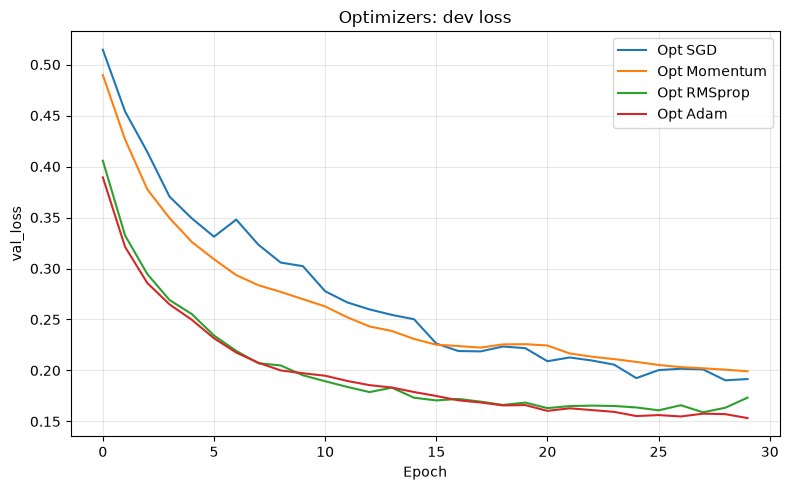

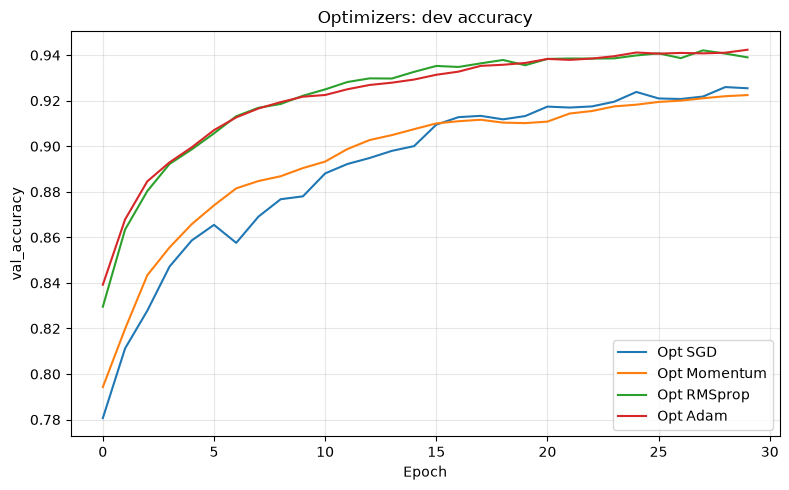

In [28]:
opt_names = ["Opt SGD", "Opt Momentum", "Opt RMSprop", "Opt Adam"]
plot_compare(histories, "val_loss", "Optimizers: dev loss", names=opt_names,
             save_path="../results/compare_optimizers_loss.png")
plot_compare(histories, "val_accuracy", "Optimizers: dev accuracy", names=opt_names,
             save_path="../results/compare_optimizers_acc.png")

### Experiment 6: batch size

Same setup as `Opt Adam` (4 hidden layers, Adam, learning rate 0.001, 30 epochs) with batch sizes 128 and 2048. The result for batch size 512 is `Opt Adam`.

Epoch 1/30
3632/3632 - 57s - 16ms/step - accuracy: 0.8069 - loss: 0.4528 - val_accuracy: 0.8504 - val_loss: 0.3554
Epoch 2/30
3632/3632 - 28s - 8ms/step - accuracy: 0.8716 - loss: 0.3087 - val_accuracy: 0.8844 - val_loss: 0.2834
Epoch 3/30
3632/3632 - 29s - 8ms/step - accuracy: 0.8955 - loss: 0.2541 - val_accuracy: 0.9004 - val_loss: 0.2466
Epoch 4/30
3632/3632 - 28s - 8ms/step - accuracy: 0.9097 - loss: 0.2217 - val_accuracy: 0.9121 - val_loss: 0.2177
Epoch 5/30
3632/3632 - 28s - 8ms/step - accuracy: 0.9182 - loss: 0.2004 - val_accuracy: 0.9173 - val_loss: 0.2076
Epoch 6/30
3632/3632 - 28s - 8ms/step - accuracy: 0.9250 - loss: 0.1850 - val_accuracy: 0.9220 - val_loss: 0.1939
Epoch 7/30
3632/3632 - 28s - 8ms/step - accuracy: 0.9296 - loss: 0.1727 - val_accuracy: 0.9211 - val_loss: 0.1933
Epoch 8/30
3632/3632 - 40s - 11ms/step - accuracy: 0.9335 - loss: 0.1633 - val_accuracy: 0.9250 - val_loss: 0.1891
Epoch 9/30
3632/3632 - 27s - 8ms/step - accuracy: 0.9369 - loss: 0.1553 - val_accuracy

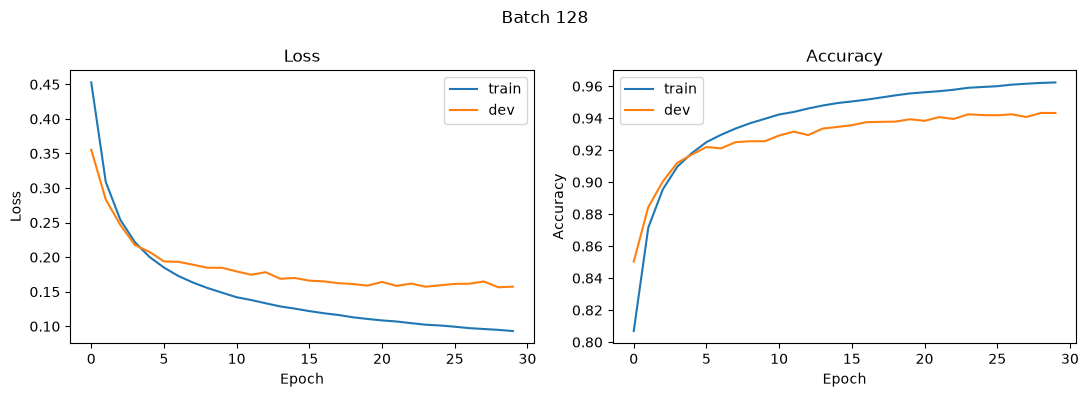

=== Batch 128 ===
              precision    recall  f1-score   support

           0       0.94      0.95      0.94     21184
           1       0.96      0.94      0.95     28330
           2       0.93      0.96      0.94      3575
           3       0.84      0.81      0.83       275
           4       0.82      0.86      0.84       950
           5       0.90      0.89      0.89      1736
           6       0.91      0.97      0.94      2051

    accuracy                           0.94     58101
   macro avg       0.90      0.91      0.90     58101
weighted avg       0.94      0.94      0.94     58101



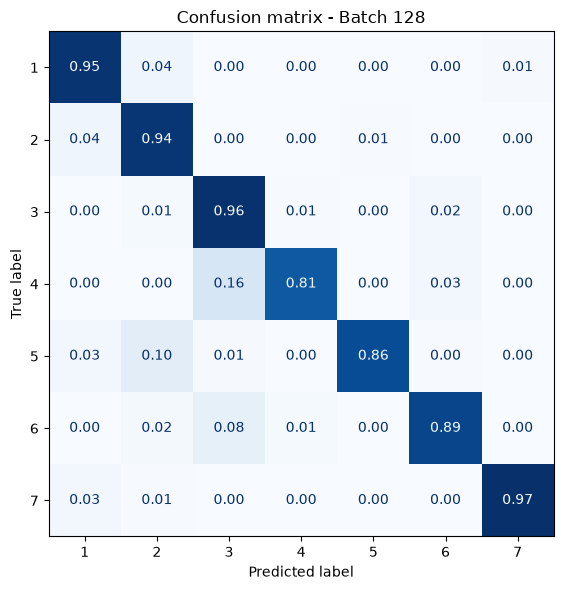

<Sequential name=sequential_9, built=True>

In [29]:
run_experiment("Batch 128", [512, 256, 128, 64], data, results,
               epochs=30, batch_size=128, histories=histories)

Epoch 1/30
227/227 - 13s - 58ms/step - accuracy: 0.7590 - loss: 0.5812 - val_accuracy: 0.8047 - val_loss: 0.4647
Epoch 2/30
227/227 - 10s - 45ms/step - accuracy: 0.8234 - loss: 0.4207 - val_accuracy: 0.8318 - val_loss: 0.3989
Epoch 3/30
227/227 - 10s - 46ms/step - accuracy: 0.8493 - loss: 0.3636 - val_accuracy: 0.8544 - val_loss: 0.3509
Epoch 4/30
227/227 - 10s - 45ms/step - accuracy: 0.8662 - loss: 0.3251 - val_accuracy: 0.8683 - val_loss: 0.3187
Epoch 5/30
227/227 - 10s - 44ms/step - accuracy: 0.8785 - loss: 0.2968 - val_accuracy: 0.8795 - val_loss: 0.2944
Epoch 6/30
227/227 - 11s - 47ms/step - accuracy: 0.8884 - loss: 0.2744 - val_accuracy: 0.8867 - val_loss: 0.2777
Epoch 7/30
227/227 - 10s - 45ms/step - accuracy: 0.8961 - loss: 0.2571 - val_accuracy: 0.8918 - val_loss: 0.2649
Epoch 8/30
227/227 - 10s - 44ms/step - accuracy: 0.9020 - loss: 0.2427 - val_accuracy: 0.8976 - val_loss: 0.2530
Epoch 9/30
227/227 - 10s - 45ms/step - accuracy: 0.9070 - loss: 0.2311 - val_accuracy: 0.9019 - 

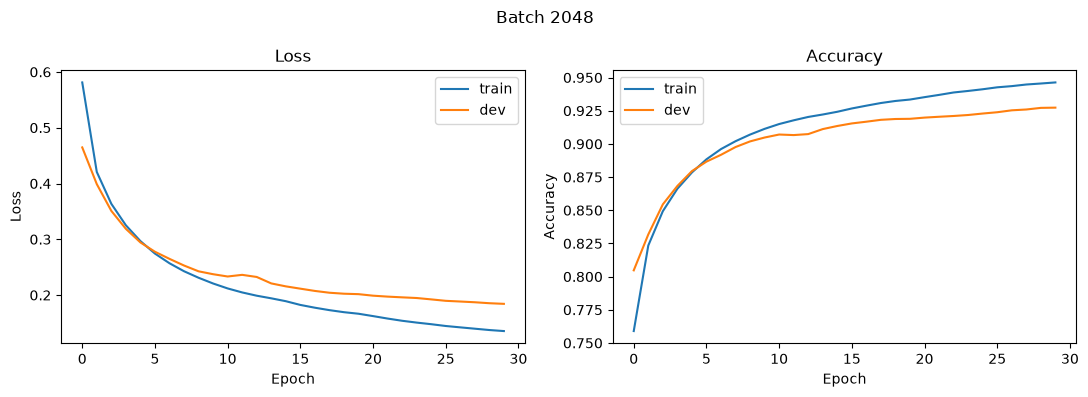

=== Batch 2048 ===
              precision    recall  f1-score   support

           0       0.95      0.90      0.92     21184
           1       0.93      0.95      0.94     28330
           2       0.91      0.93      0.92      3575
           3       0.74      0.90      0.81       275
           4       0.80      0.84      0.82       950
           5       0.82      0.87      0.85      1736
           6       0.93      0.95      0.94      2051

    accuracy                           0.93     58101
   macro avg       0.87      0.91      0.89     58101
weighted avg       0.93      0.93      0.93     58101



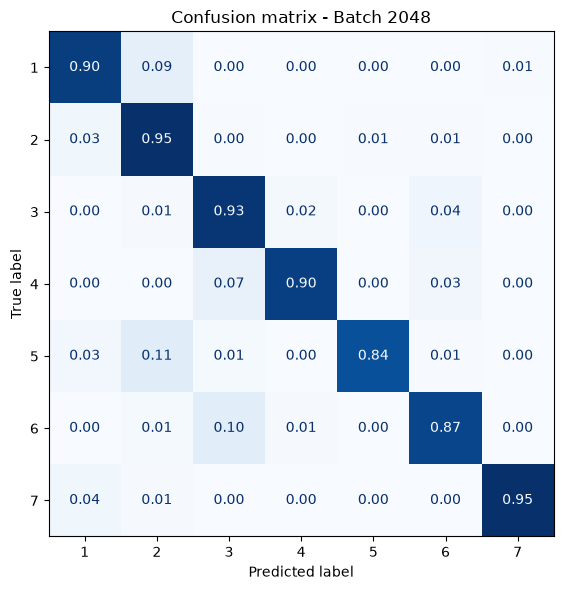

<Sequential name=sequential_10, built=True>

In [30]:
run_experiment("Batch 2048", [512, 256, 128, 64], data, results,
               epochs=30, batch_size=2048, histories=histories)

In [31]:
pd.DataFrame(results).to_csv("../results/nn_results.csv", index=False)

with open("../results/histories.json", "w") as f:
    json.dump(histories, f, default=float)

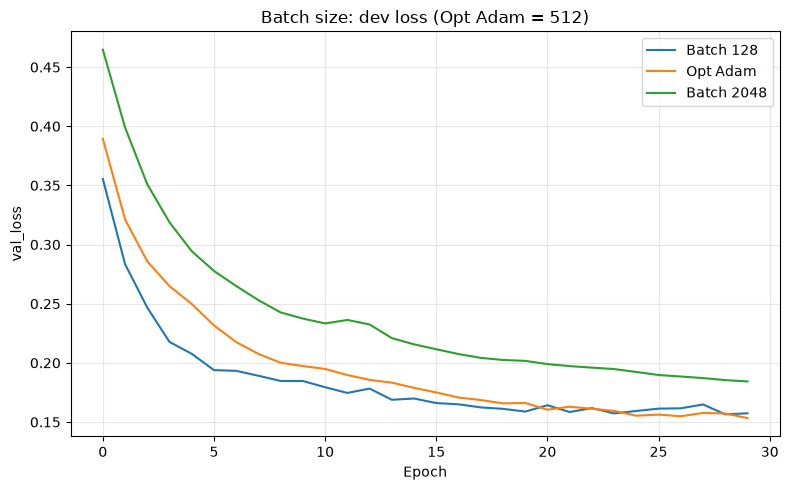

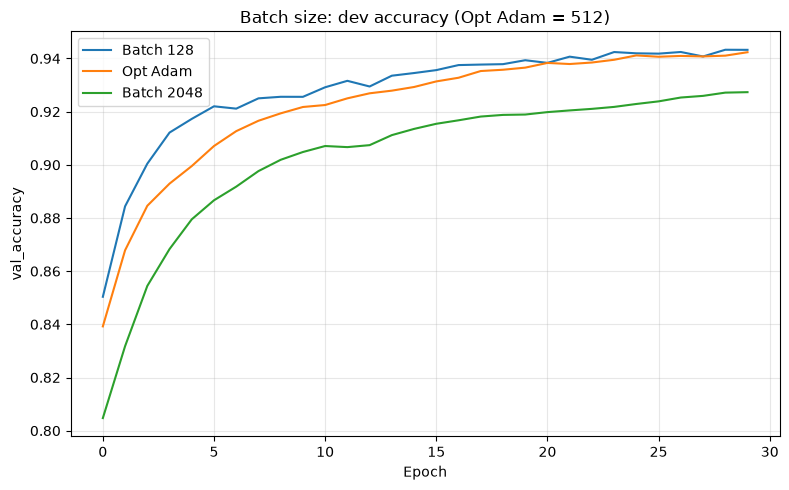

In [32]:
bs_names = ["Batch 128", "Opt Adam", "Batch 2048"]
plot_compare(histories, "val_loss", "Batch size: dev loss (Opt Adam = 512)", names=bs_names,
             save_path="../results/compare_batch_loss.png")
plot_compare(histories, "val_accuracy", "Batch size: dev accuracy (Opt Adam = 512)", names=bs_names,
             save_path="../results/compare_batch_acc.png")

**Observations (batch size, 30 epochs, Adam)**
- Batch 128 and 512 reach the same quality: dev accuracy 0.943 vs 0.942, and macro F1 0.904 for both. Batch 128 learns faster per epoch (dev accuracy 0.917 at epoch 5, versus 0.900 for 512), but its dev loss flattens earlier (0.157 vs 0.153) and its training accuracy is higher (0.959 vs 0.956), so it overfits slightly more.
- The price is speed: about 28 seconds per epoch for batch 128 and 13 for batch 512. For the same time, batch 512 is better: after about 260 seconds it has dev accuracy 0.937 (20 epochs), while batch 128 has 0.926 (10 epochs).
- Batch 2048 learns slower per epoch (dev accuracy 0.905 at epoch 10, versus 0.922 for 512) and ends lower after 30 epochs (accuracy 0.927, macro F1 0.886). It was still improving. It has fewer updates per epoch, and it is not much faster on this CPU (about 10 seconds per epoch vs 13).
- Batch size 512 is the best compromise between speed and quality and stays the default.

In [33]:
results_df = pd.DataFrame(results)
results_df

,model,accuracy,macro_f1,params,train_acc
0,NN 1x64,0.821414,0.733075,3975,0.822314
1,"NN 2x(128,64)",0.881413,0.808019,15751,0.885615
2,"NN 3x(256,128,64)",0.913100,0.859446,55687,0.922659
3,"NN 4x(512,256,128,64)",0.936559,0.900783,201095,0.947830
4,NN best 60ep,0.948744,0.916265,201095,0.964471
5,NN L2 1e-4,0.933323,0.886659,201095,0.944330
6,NN Dropout 0.2,0.939399,0.907603,201095,0.948314
7,Opt SGD,0.925457,0.880842,201095,0.937525
8,Opt Momentum,0.922463,0.873523,201095,0.934414
9,Opt RMSprop,0.939020,0.897515,201095,0.952731
